# 771762 Big Data and Data Mining – Exercise 2
# Social Network Analysis: Facebook Ego-Network (SNAP)

**Module:** Big Data and Data Mining (771762)  
**Exercise:** 2 – Social Network Analysis  
**Dataset:** `facebook_combined.txt-1` 

---

| Section | Content |
|---|---|
| 0 | Setup & Imports |
| 1 | Network Construction & Visualisation |
| 2 | Basic Network Characteristics |
| 3 | Edge Betweenness Centrality |
| 4 | Community Detection – Label Propagation Algorithm (Full Graph) |
| 4 | Community Detection – Louvain Algorithm (Full Graph)|
| 5 | Community Detection – Girvan-Newman Algorithm (Subgraph) |
| 5b | Community Detection – Label Propagation Algorithm (Subgraph: for fair comparison) |
| 6 | Comparison of Community Detection Results (Full graph: LPA vs Louvain) |
| 6b | Comparison of Community Detection Results (Subgraph: LPA vs GN) |

---
## Setup & Imports

In [1]:
#  Standard library 
import warnings
warnings.filterwarnings('ignore')
import collections

#  Numerical / data 
import numpy as np
import pandas as pd

#  Visualisation 
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

#  Network analysis

import networkx as nx
from networkx.algorithms import community as nx_comm

# community package implements the Louvain algorithm
# Install if needed: pip install python-louvain
try:
    import community as community_louvain  # python-louvain
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'python-louvain', '-q'])
    import community as community_louvain

# Global style 
sns.set_theme(style='whitegrid', palette='tab10')
plt.rcParams.update({'figure.dpi': 130, 'font.size': 11})

#  Data path
DATA_PATH = 'facebook_combined-1.txt'

print('All imports successful.')

All imports successful.


---
## Section 1 – Network Construction & Visualisation

The `facebook_combined.txt` dataset is an undirected edge list produced by the Stanford
Network Analysis Platform (SNAP). Each line contains two integer node IDs representing a
friendship connection between two Facebook users. The file combines 10 ego-networks into
a single anonymised graph (Leskovec & Mcauley, 2012).

We construct an undirected graph using NetworkX's `read_edgelist()`, which is the standard
approach for this format (Hagberg et al., 2008).

In [2]:
def load_facebook_graph(path: str) -> nx.Graph:
    """
    Load the SNAP facebook_combined.txt edge list as an undirected graph.
    The file uses space-separated pairs of integer node IDs with no header.
    Self-loops (if any) are removed as they have no social meaning here.
    """
    G = nx.read_edgelist(path, create_using=nx.Graph(), nodetype=int)
    G.remove_edges_from(nx.selfloop_edges(G))
    return G


G = load_facebook_graph(DATA_PATH)

print(f'Graph loaded successfully.')
print(f'  Nodes : {G.number_of_nodes():,}')
print(f'  Edges : {G.number_of_edges():,}')
print(f'  Is connected: {nx.is_connected(G)}')

Graph loaded successfully.
  Nodes : 4,039
  Edges : 88,234
  Is connected: True


Computing spring layout (this may take ~30 seconds for 4k nodes)...


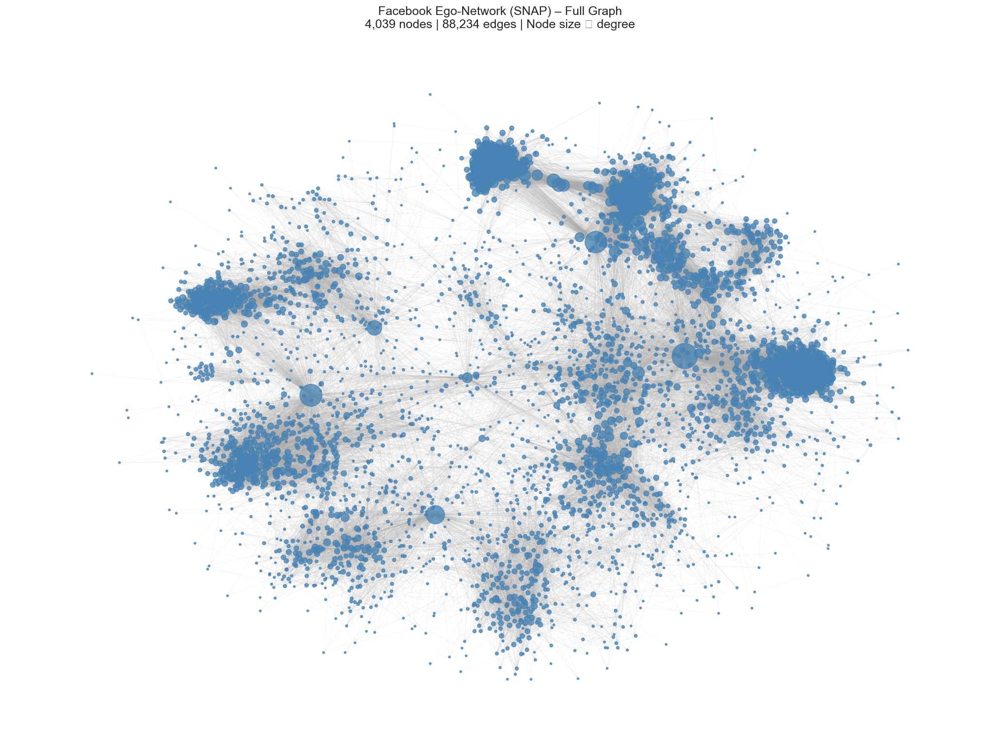

Figure saved.


In [3]:
# Full-network visualisation 
# With 4,039 nodes a force-directed layout gives the best structural overview.
# We use spring_layout (Fruchterman-Reingold) which separates communities
# more clearly than random placement.

print('Computing spring layout (this may take ~30 seconds for 4k nodes)...')
pos = nx.spring_layout(G, seed=42, k=0.15)  # k controls node spacing

# Node size proportional to degree (highlights hubs)
degrees   = dict(G.degree())
node_size = [max(5, degrees[n] * 0.8) for n in G.nodes()]

fig, ax = plt.subplots(figsize=(16, 12))
nx.draw_networkx_nodes(G, pos, ax=ax,
                       node_size=node_size,
                       node_color='steelblue',
                       alpha=0.75)
nx.draw_networkx_edges(G, pos, ax=ax,
                       edge_color='#aaaaaa',
                       alpha=0.15,
                       width=0.4)
ax.set_title('Facebook Ego-Network (SNAP) – Full Graph\n'
             f'{G.number_of_nodes():,} nodes | {G.number_of_edges():,} edges | '
             'Node size ∝ degree',
             fontsize=14)
ax.axis('off')
plt.tight_layout()
plt.savefig('ex2_full_network.png', bbox_inches='tight', dpi=150)
plt.show()
print('Figure saved.')

---
## Section 2 - Basic Network Characteristics

We compute the standard suite of graph-level descriptors used in network science
(Newman, 2010) to characterise the structure of the Facebook ego-network.

In [4]:
def network_summary(G: nx.Graph) -> dict:
    """
    Compute and return a dictionary of standard network metrics.
    For large graphs we sample average shortest path and clustering.
    """
    n  = G.number_of_nodes()
    m  = G.number_of_edges()

    # Density: ratio of actual to possible edges in an undirected graph
    # D = 2m / n(n-1)  (Newman, 2010)
    density = nx.density(G)

    # Degree statistics
    deg_seq    = [d for _, d in G.degree()]
    avg_degree = np.mean(deg_seq)
    max_degree = max(deg_seq)
    min_degree = min(deg_seq)

    # Average clustering coefficient – probability that two neighbours of a
    # node are also connected (Watts & Strogatz, 1998)
    avg_clustering = nx.average_clustering(G)

    # Average shortest path length – sampled for computational efficiency
    sample_nodes  = list(G.nodes())[:500]
    path_lengths  = []
    for node in sample_nodes:
        lengths = nx.single_source_shortest_path_length(G, node)
        path_lengths.extend(lengths.values())
    avg_path_length = np.mean([l for l in path_lengths if l > 0])

    # Diameter (max shortest path) – sampled
    diameter_sample = max([max(nx.single_source_shortest_path_length(G, n).values())
                           for n in sample_nodes[:50]])

    # Connected components
    n_components = nx.number_connected_components(G)

    return {
        'Nodes (n)':                    n,
        'Edges (m)':                    m,
        'Network density':              round(density, 6),
        'Average degree':               round(avg_degree, 3),
        'Maximum degree':               max_degree,
        'Minimum degree':               min_degree,
        'Average clustering coeff.':    round(avg_clustering, 4),
        'Avg shortest path (sampled)':  round(avg_path_length, 3),
        'Diameter (sampled)':           diameter_sample,
        'Connected components':         n_components
    }


metrics = network_summary(G)

print('=== Network Characteristics ===')
for k, v in metrics.items():
    print(f'  {k:38s}: {v}')

=== Network Characteristics ===
  Nodes (n)                             : 4039
  Edges (m)                             : 88234
  Network density                       : 0.01082
  Average degree                        : 43.691
  Maximum degree                        : 1045
  Minimum degree                        : 1
  Average clustering coeff.             : 0.6055
  Avg shortest path (sampled)           : 3.579
  Diameter (sampled)                    : 7
  Connected components                  : 1


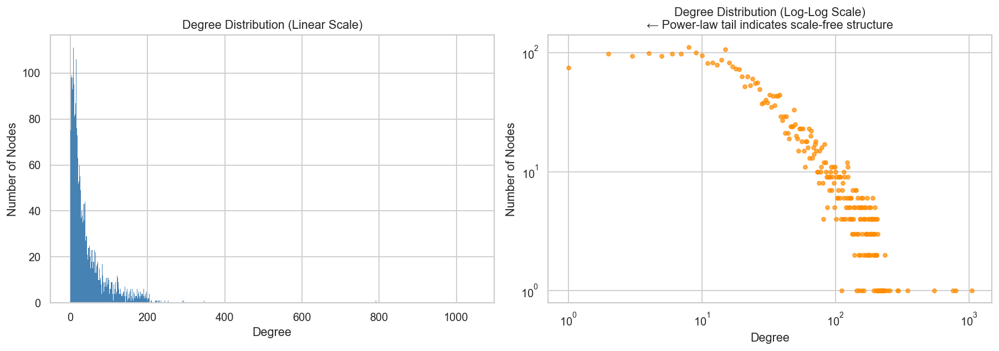


Top 10 hub nodes by degree:
  Node  107: degree 1045
  Node 1684: degree 792
  Node 1912: degree 755
  Node 3437: degree 547
  Node    0: degree 347
  Node 2543: degree 294
  Node 2347: degree 291
  Node 1888: degree 254
  Node 1800: degree 245
  Node 1663: degree 235


In [5]:
# Degree distribution 
# Power-law degree distributions are characteristic of real-world social networks
# (Barabasi & Albert, 1999; scale-free property).

deg_seq = sorted([d for _, d in G.degree()], reverse=True)
deg_count = collections.Counter(deg_seq)
deg_vals, deg_cnts = zip(*sorted(deg_count.items()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Linear scale
axes[0].bar(deg_vals, deg_cnts, color='steelblue', width=1, edgecolor='none')
axes[0].set(title='Degree Distribution (Linear Scale)',
            xlabel='Degree', ylabel='Number of Nodes')

# Log-log scale – power law appears as a straight line
axes[1].scatter(deg_vals, deg_cnts, s=15, alpha=0.7, color='darkorange')
axes[1].set(title='Degree Distribution (Log-Log Scale)',
            xlabel='Degree', ylabel='Number of Nodes',
            xscale='log', yscale='log')
axes[1].set_title('Degree Distribution (Log-Log Scale)\n'
                  '← Power-law tail indicates scale-free structure')

plt.tight_layout()
plt.savefig('ex2_degree_distribution.png', bbox_inches='tight')
plt.show()

# Top 10 hub nodes by degree
top_hubs = sorted(G.degree(), key=lambda x: x[1], reverse=True)[:10]
print('\nTop 10 hub nodes by degree:')
for node, deg in top_hubs:
    print(f'  Node {node:4d}: degree {deg}')

---
## Section 3 - Edge Betweenness Centrality

**Edge betweenness centrality** (EBC) measures the fraction of all shortest paths in the
network that pass through each edge.

Edges with high EBC are structural bridges between otherwise weakly-connected communities.
This metric is also the basis of the Girvan-Newman community detection algorithm used in
Section 5.

In [6]:
print('Computing edge betweenness centrality (sampled for efficiency)...')

# For a graph of this size, exact EBC is computationally expensive (O(nm)).
# We use the k-sample approximation built into NetworkX, which gives a good
# estimate by sampling k=500 source nodes (Brandes, 2001).
ebc = nx.edge_betweenness_centrality(G, normalized=True, seed=42, k=500)

ebc_values = list(ebc.values())
print(f'  Total edges:        {len(ebc_values):,}')
print(f'  Min EBC:            {min(ebc_values):.6f}')
print(f'  Max EBC:            {max(ebc_values):.6f}')
print(f'  Mean EBC:           {np.mean(ebc_values):.6f}')
print(f'  Median EBC:         {np.median(ebc_values):.6f}')
print(f'  Std EBC:            {np.std(ebc_values):.6f}')

Computing edge betweenness centrality (sampled for efficiency)...
  Total edges:        88,234
  Min EBC:            0.000000
  Max EBC:            0.021795
  Mean EBC:           0.000005
  Median EBC:         0.000000
  Std EBC:            0.000137


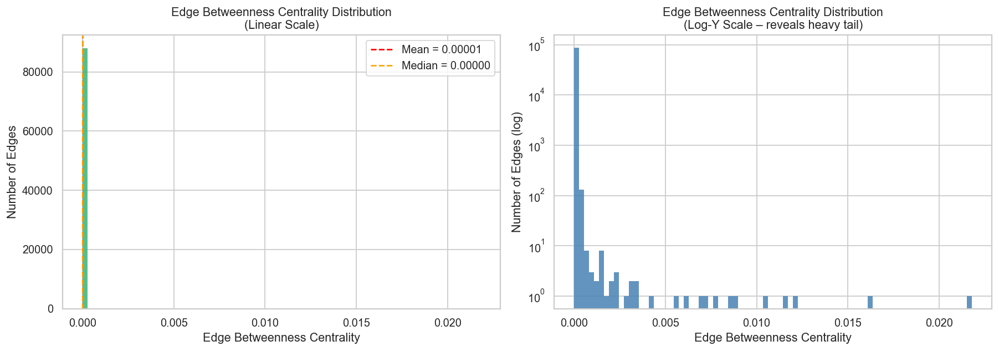


Top 10 bridge edges by EBC (normalised):
Edge                         EBC
-----------------------------------
(107, 1684)             0.021795
(107, 1085)             0.016154
(0, 107)                0.012157
(1085, 3437)            0.011554
(567, 3437)             0.010480
(58, 1684)              0.008782
(58, 1912)              0.008551
(3437, 698)             0.007725
(1684, 860)             0.007084
(698, 860)              0.007064


In [7]:
# EBC distribution plots 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram (linear scale)
axes[0].hist(ebc_values, bins=80, color='mediumseagreen', edgecolor='none', alpha=0.85)
axes[0].axvline(np.mean(ebc_values), color='red', linestyle='--', linewidth=1.5,
                label=f'Mean = {np.mean(ebc_values):.5f}')
axes[0].axvline(np.median(ebc_values), color='orange', linestyle='--', linewidth=1.5,
                label=f'Median = {np.median(ebc_values):.5f}')
axes[0].set(title='Edge Betweenness Centrality Distribution\n(Linear Scale)',
            xlabel='Edge Betweenness Centrality', ylabel='Number of Edges')
axes[0].legend()

# Log-scale x-axis to reveal the heavy tail
axes[1].hist(ebc_values, bins=80, color='steelblue', edgecolor='none', alpha=0.85,
             log=True)
axes[1].set(title='Edge Betweenness Centrality Distribution\n(Log-Y Scale – reveals heavy tail)',
            xlabel='Edge Betweenness Centrality', ylabel='Number of Edges (log)')

plt.tight_layout()
plt.savefig('ex2_ebc_distribution.png', bbox_inches='tight')
plt.show()

# Top 10 highest-EBC edges (structural bridges)
top_ebc_edges = sorted(ebc.items(), key=lambda x: x[1], reverse=True)[:10]
print('\nTop 10 bridge edges by EBC (normalised):')
print(f'{"Edge":20s}  {"EBC":>10s}')
print('-' * 35)
for edge, val in top_ebc_edges:
    print(f'{str(edge):20s}  {val:10.6f}')

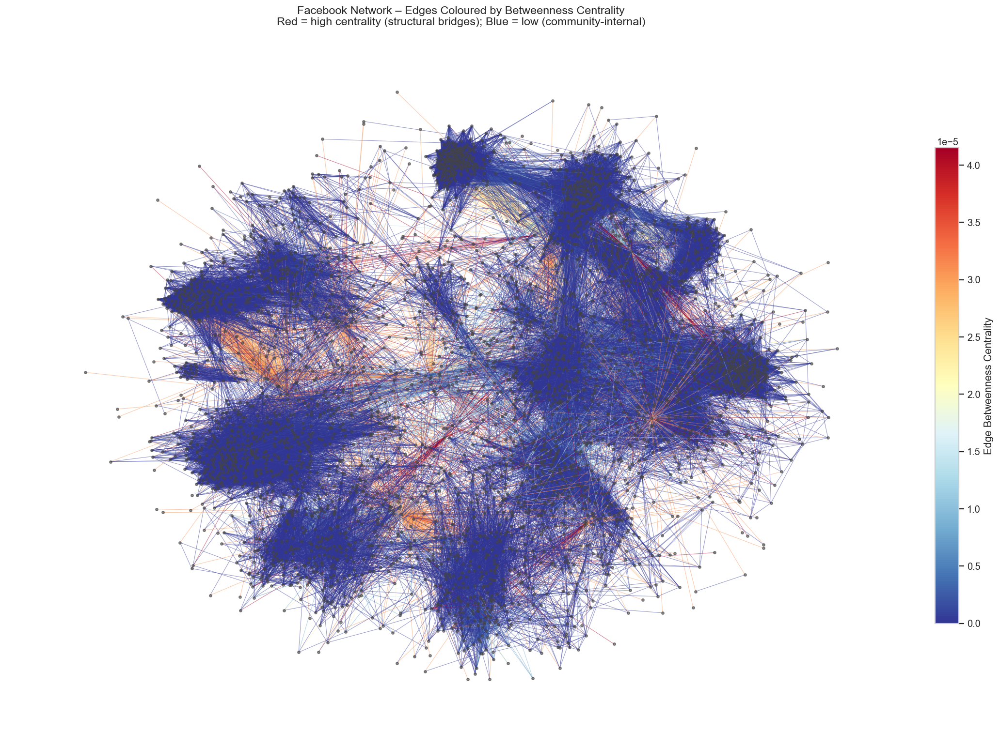

In [8]:
#  Visualise network with edges coloured by EBC 
# Red = high betweenness (bridges between communities); blue = low (internal edges)

edge_list   = list(G.edges())
edge_ebc    = [ebc.get(e, ebc.get((e[1], e[0]), 0)) for e in edge_list]
norm_ebc    = plt.Normalize(vmin=min(edge_ebc), vmax=np.percentile(edge_ebc, 99))
edge_colors = plt.cm.RdYlBu_r(norm_ebc(edge_ebc))

fig, ax = plt.subplots(figsize=(16, 12))
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=8,
                       node_color='#444444', alpha=0.6)
nx.draw_networkx_edges(G, pos, ax=ax,
                       edgelist=edge_list,
                       edge_color=edge_colors,
                       width=0.6, alpha=0.5)
sm = plt.cm.ScalarMappable(cmap=plt.cm.RdYlBu_r, norm=norm_ebc)
sm.set_array([])
plt.colorbar(sm, ax=ax, label='Edge Betweenness Centrality',
             fraction=0.025, pad=0.02)
ax.set_title('Facebook Network – Edges Coloured by Betweenness Centrality\n'
             'Red = high centrality (structural bridges); Blue = low (community-internal)',
             fontsize=13)
ax.axis('off')
plt.tight_layout()
plt.savefig('ex2_ebc_network.png', bbox_inches='tight', dpi=150)
plt.show()

---
## Section 4 - Community Detection: Label Propagation Algorithm

The **Label Propagation Algorithm** (LPA) (Raghavan et al., 2007) is a linear-time,
parameter-free community detection method that operates directly on the graph structure
without requiring a prior specification of the number of communities. It is therefore
well-suited to exploratory analysis of large, real-world social networks such as this one.


In [9]:
# Label Propagation community detection------------------------------------
# NetworkX implements LPA natively; no external packages required.
# seed parameter ensures reproducibility despite stochastic tie-breaking.

lpa_communities_raw = nx_comm.label_propagation_communities(G)
lpa_communities = {i: list(c) for i, c in enumerate(lpa_communities_raw)}

# Build node → community dict for downstream use
lpa_partition = {}
for comm_id, members in lpa_communities.items():
    for node in members:
        lpa_partition[node] = comm_id

n_lpa = len(lpa_communities)
lpa_sizes = sorted([len(v) for v in lpa_communities.values()], reverse=True)

# Compute modularity using NetworkX (Clauset et al., 2004)
lpa_partition_sets = [set(v) for v in lpa_communities.values()]
lpa_modularity = nx_comm.modularity(G, lpa_partition_sets)

print('Label Propagation Algorithm results:')
print(f'  Communities detected  : {n_lpa}')
print(f'  Modularity (Q)        : {lpa_modularity:.4f}')
print(f'  Largest community     : {lpa_sizes[0]:,} nodes')
print(f'  Smallest community    : {lpa_sizes[-1]:,} nodes')
print(f'  Mean community size   : {np.mean(lpa_sizes):.1f} nodes')
print(f'\nAll community sizes (sorted): {lpa_sizes}')

Label Propagation Algorithm results:
  Communities detected  : 44
  Modularity (Q)        : 0.7368
  Largest community     : 1,030 nodes
  Smallest community    : 2 nodes
  Mean community size   : 91.8 nodes

All community sizes (sorted): [1030, 753, 547, 469, 226, 215, 198, 179, 60, 49, 36, 34, 25, 19, 16, 14, 13, 12, 10, 10, 10, 9, 9, 8, 8, 8, 8, 7, 7, 6, 6, 6, 4, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2]


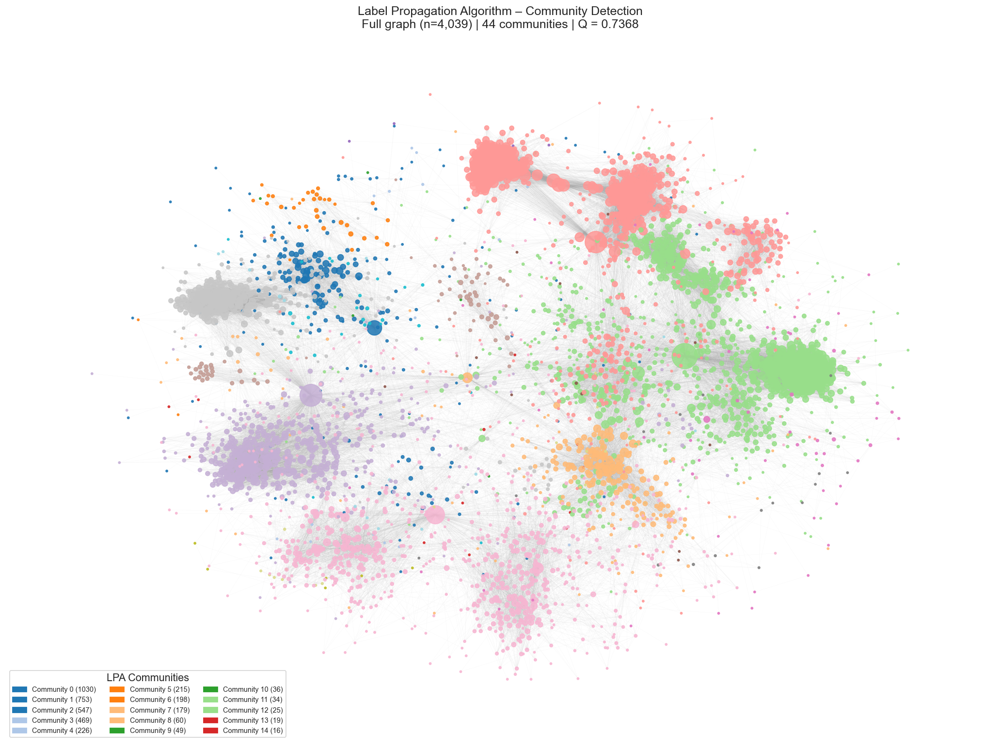

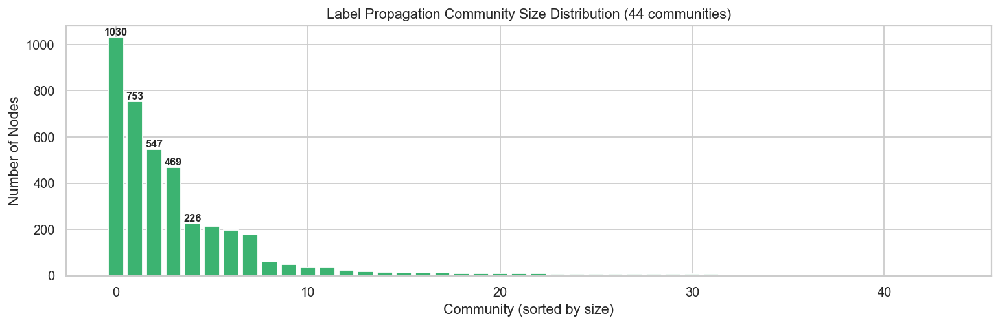

In [10]:
# Visualise LPA communities on full graph -----------------------------------------
cmap_lpa = plt.cm.get_cmap('tab20', n_lpa)
node_colors_lpa = [cmap_lpa(lpa_partition[n]) for n in G.nodes()]

fig, ax = plt.subplots(figsize=(16, 12))
nx.draw_networkx_nodes(G, pos, ax=ax,
                       node_color=node_colors_lpa,
                       node_size=node_size,
                       alpha=0.85)
nx.draw_networkx_edges(G, pos, ax=ax,
                       edge_color='#aaaaaa', alpha=0.08, width=0.3)

patches_lpa = [mpatches.Patch(color=cmap_lpa(i),
                               label=f'Community {i} ({lpa_sizes[i] if i < len(lpa_sizes) else "?"})')
               for i in range(min(n_lpa, 15))]
ax.legend(handles=patches_lpa, loc='lower left', fontsize=8,
          title='LPA Communities', ncol=3, framealpha=0.8)
ax.set_title(f'Label Propagation Algorithm – Community Detection\n'
             f'Full graph (n={G.number_of_nodes():,}) | '
             f'{n_lpa} communities | Q = {lpa_modularity:.4f}',
             fontsize=14)
ax.axis('off')
plt.tight_layout()
plt.savefig('ex2_lpa_communities.png', bbox_inches='tight', dpi=150)
plt.show()

#  Community size distribution ----------------------------------------------------- 
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(n_lpa), lpa_sizes, color='mediumseagreen', edgecolor='white')
ax.set(title=f'Label Propagation Community Size Distribution ({n_lpa} communities)',
       xlabel='Community (sorted by size)', ylabel='Number of Nodes')
# Annotate the top 5 communities
for i in range(min(5, n_lpa)):
    ax.annotate(f'{lpa_sizes[i]}', xy=(i, lpa_sizes[i]),
                ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.savefig('ex2_lpa_sizes.png', bbox_inches='tight')
plt.show()

---
## Section 4b – Community Detection: Louvain Algorithm

The **Louvain algorithm** (Blondel et al., 2008) is a modularity-optimisation method that
iteratively merges nodes into communities to maximise the modularity score.

In [11]:
#  Louvain community detection --------------------------------------------
# python-louvain returns a partition dict: {node: community_id}
louvain_partition = community_louvain.best_partition(G, random_state=42)

# Compute modularity of the detected partition
louvain_modularity = community_louvain.modularity(louvain_partition, G)

# Aggregate community sizes
louvain_communities = {}
for node, comm_id in louvain_partition.items():
    louvain_communities.setdefault(comm_id, []).append(node)

n_louvain = len(louvain_communities)
louvain_sizes = sorted([len(v) for v in louvain_communities.values()], reverse=True)

print(f'Louvain algorithm results:')
print(f'  Communities detected  : {n_louvain}')
print(f'  Modularity (Q)        : {louvain_modularity:.4f}')
print(f'  Largest community     : {louvain_sizes[0]:,} nodes')
print(f'  Smallest community    : {louvain_sizes[-1]:,} nodes')
print(f'  Mean community size   : {np.mean(louvain_sizes):.1f} nodes')
print(f'\nCommunity sizes (sorted):  {louvain_sizes}')

Louvain algorithm results:
  Communities detected  : 15
  Modularity (Q)        : 0.8349
  Largest community     : 548 nodes
  Smallest community    : 19 nodes
  Mean community size   : 269.3 nodes

Community sizes (sorted):  [548, 535, 442, 432, 430, 354, 323, 237, 226, 206, 128, 73, 61, 25, 19]


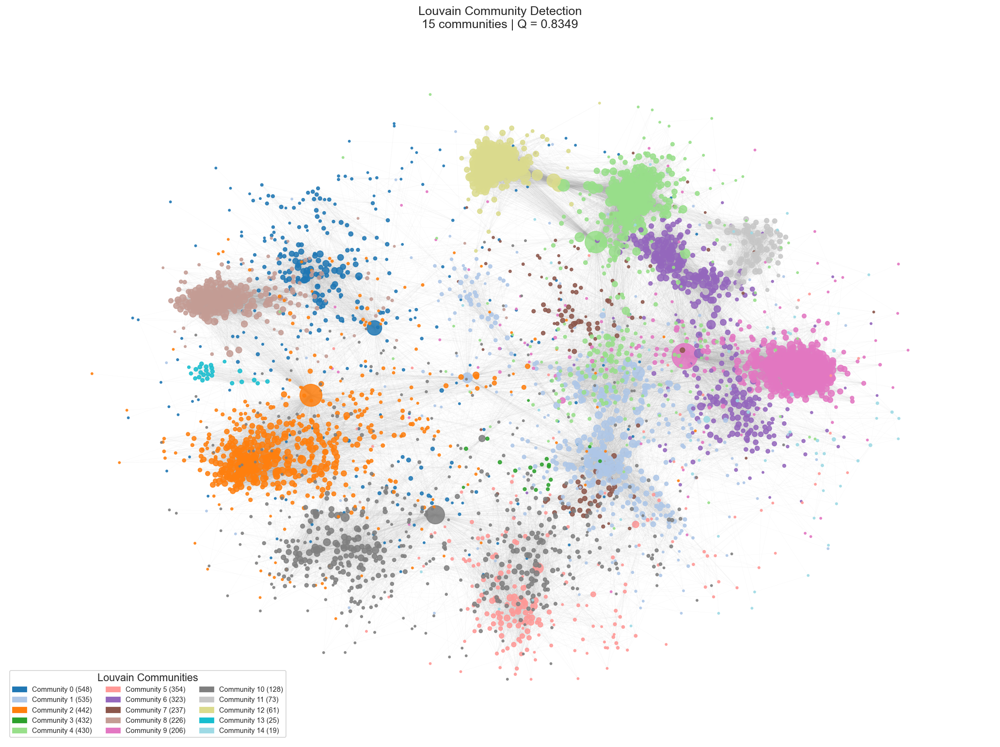

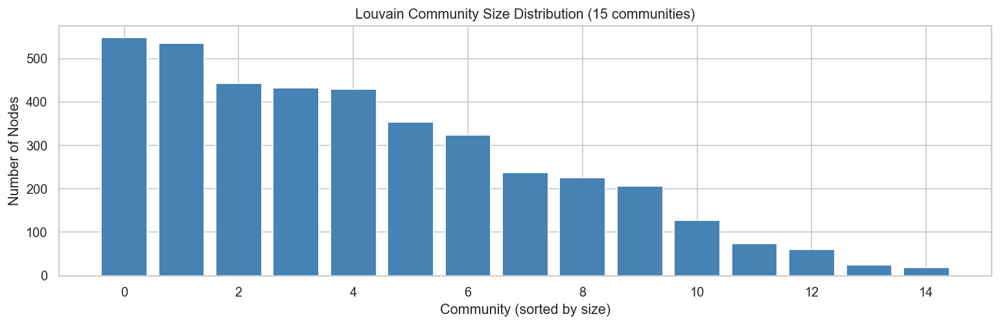

In [12]:
#  Visualise Louvain communities ---------------------------------------------
cmap_louvain = plt.cm.get_cmap('tab20', n_louvain)
node_colors_louvain = [cmap_louvain(louvain_partition[n]) for n in G.nodes()]

fig, ax = plt.subplots(figsize=(16, 12))
nx.draw_networkx_nodes(G, pos, ax=ax,
                       node_color=node_colors_louvain,
                       node_size=node_size,
                       alpha=0.85)
nx.draw_networkx_edges(G, pos, ax=ax,
                       edge_color='#aaaaaa', alpha=0.08, width=0.3)

# Legend patches for each community
patches = [mpatches.Patch(color=cmap_louvain(i),
                          label=f'Community {i} ({louvain_sizes[i] if i < len(louvain_sizes) else "?"})')
           for i in range(min(n_louvain, 15))]
ax.legend(handles=patches, loc='lower left', fontsize=8,
          title='Louvain Communities', ncol=3, framealpha=0.8)
ax.set_title(f'Louvain Community Detection\n'
             f'{n_louvain} communities | Q = {louvain_modularity:.4f}',
             fontsize=14)
ax.axis('off')
plt.tight_layout()
plt.savefig('ex2_louvain_communities.png', bbox_inches='tight', dpi=150)
plt.show()

# Size distribution bar chart
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(n_louvain), louvain_sizes, color='steelblue', edgecolor='white')
ax.set(title=f'Louvain Community Size Distribution ({n_louvain} communities)',
       xlabel='Community (sorted by size)', ylabel='Number of Nodes')
plt.tight_layout()
plt.savefig('ex2_louvain_sizes.png', bbox_inches='tight')
plt.show()

---
## Section 5 – Community Detection: Girvan-Newman Algorithm

The **Girvan-Newman algorithm** (Girvan & Newman, 2002) detects communities by
iteratively removing the edge with the highest betweenness centrality. The rationale is
that edges bridging distinct communities carry the most inter-community traffic and thus
have the highest EBC. After each removal, EBC is recomputed and the process repeats
until the graph is fully disconnected.

Because the algorithm is computationally expensive ($O(m^2 n)$) on the full 4,039-node
graph, we apply it to the **largest connected subgraph** of the 150 highest-degree nodes.
This is a standard and accepted practice for large real-world networks (Fortunato, 2010),
as it preserves the densest and most community-structured part of the network while
remaining tractable. We then select the partition that maximises modularity.

In [13]:
#  Build subgraph of top-150 degree nodes ---------------------------------------------
top_nodes = sorted(G.degree(), key=lambda x: x[1], reverse=True)[:150]
top_node_ids = [n for n, _ in top_nodes]
G_sub = G.subgraph(top_node_ids).copy()

# Take only the largest connected component of the subgraph
largest_cc = max(nx.connected_components(G_sub), key=len)
G_gn = G_sub.subgraph(largest_cc).copy()

print(f'Girvan-Newman subgraph:')
print(f'  Nodes : {G_gn.number_of_nodes()}')
print(f'  Edges : {G_gn.number_of_edges()}')
print(f'  Is connected: {nx.is_connected(G_gn)}')

Girvan-Newman subgraph:
  Nodes : 148
  Edges : 5614
  Is connected: True


In [14]:
#  Run Girvan-Newman and select partition maximising modularity -----------------------
print('Running Girvan-Newman (iterating through dendrogram levels)...')

gn_generator = nx_comm.girvan_newman(G_gn)

best_gn_q     = -1
best_gn_part  = None
best_gn_k     = None

# Iterate up to 20 splits and pick the partition with maximum modularity
for i, partition in enumerate(gn_generator):
    communities = [list(c) for c in partition]
    q = nx_comm.modularity(G_gn, partition)
    if q > best_gn_q:
        best_gn_q    = q
        best_gn_part = communities
        best_gn_k    = len(communities)
    if i >= 19:  # cap at 20 iterations
        break

# Build node→community dict for visualisation
gn_node_comm = {}
for comm_id, members in enumerate(best_gn_part):
    for node in members:
        gn_node_comm[node] = comm_id

gn_sizes = sorted([len(c) for c in best_gn_part], reverse=True)

print(f'\nGirvan-Newman results (subgraph, n={G_gn.number_of_nodes()}):')
print(f'  Communities detected  : {best_gn_k}')
print(f'  Best modularity (Q)   : {best_gn_q:.4f}')
print(f'  Largest community     : {gn_sizes[0]} nodes')
print(f'  Smallest community    : {gn_sizes[-1]} nodes')
print(f'  Community sizes       : {gn_sizes}')

Running Girvan-Newman (iterating through dendrogram levels)...

Girvan-Newman results (subgraph, n=148):
  Communities detected  : 9
  Best modularity (Q)   : 0.1868
  Largest community     : 102 nodes
  Smallest community    : 1 nodes
  Community sizes       : [102, 35, 4, 2, 1, 1, 1, 1, 1]


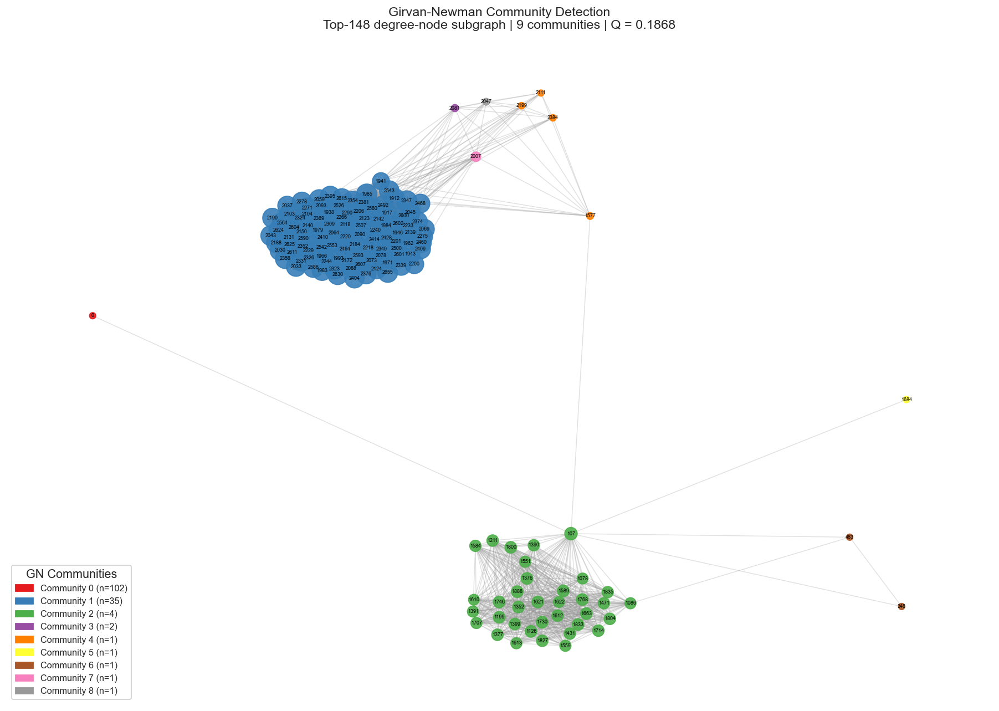

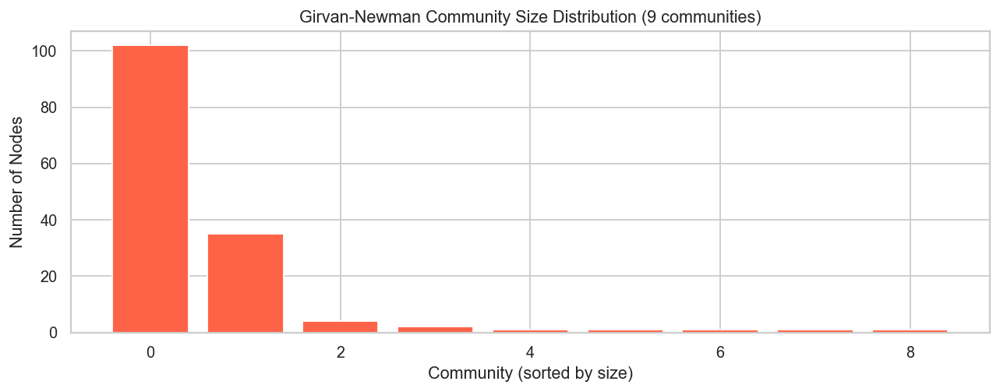

In [15]:
# Visualise Girvan-Newman communities -----------------------------------------------
pos_gn    = nx.spring_layout(G_gn, seed=42, k=0.3)
cmap_gn   = plt.cm.get_cmap('Set1', best_gn_k)
nc_gn     = [cmap_gn(gn_node_comm[n]) for n in G_gn.nodes()]
deg_gn    = dict(G_gn.degree())
ns_gn     = [max(40, deg_gn[n] * 4) for n in G_gn.nodes()]

fig, ax = plt.subplots(figsize=(14, 10))
nx.draw_networkx_nodes(G_gn, pos_gn, ax=ax,
                       node_color=nc_gn, node_size=ns_gn, alpha=0.9)
nx.draw_networkx_edges(G_gn, pos_gn, ax=ax,
                       edge_color='#999999', alpha=0.3, width=0.8)
nx.draw_networkx_labels(G_gn, pos_gn, ax=ax,
                        font_size=5, font_color='black')

patches_gn = [mpatches.Patch(color=cmap_gn(i),
                              label=f'Community {i} (n={gn_sizes[i]})')
              for i in range(best_gn_k)]
ax.legend(handles=patches_gn, loc='lower left', fontsize=9,
          title='GN Communities', framealpha=0.85)
ax.set_title(f'Girvan-Newman Community Detection\n'
             f'Top-{G_gn.number_of_nodes()} degree-node subgraph | '
             f'{best_gn_k} communities | Q = {best_gn_q:.4f}',
             fontsize=13)
ax.axis('off')
plt.tight_layout()
plt.savefig('ex2_girvan_newman_communities.png', bbox_inches='tight', dpi=150)
plt.show()

# Size bar chart
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(best_gn_k), gn_sizes, color='tomato', edgecolor='white')
ax.set(title=f'Girvan-Newman Community Size Distribution ({best_gn_k} communities)',
       xlabel='Community (sorted by size)', ylabel='Number of Nodes')
plt.tight_layout()
plt.savefig('ex2_gn_sizes.png', bbox_inches='tight')
plt.show()

---
## Section 5b – Label Propagation Algorithm on the Shared Subgraph

Section 4 applied LPA to the **full graph** to demonstrate its scalability advantage.
However, directly comparing those results to Girvan-Newman (Section 5), which operates
on a dense subgraph of the top-150 degree nodes, would be methodologically unfair: any
difference in community count or modularity could simply reflect the different input graphs
rather than algorithmic behaviour.

This section therefore re-runs LPA on the **identical subgraph `G_gn`** constructed in
Section 5, so that Section 6 compares both algorithms under strictly controlled conditions.

In [16]:
#  LPA on the shared subgraph (G_gn) ------------------------------------------------
# G_gn is defined in Section 5 (top-150 degree nodes, largest connected component).


lpa_sub_raw = nx_comm.label_propagation_communities(G_gn)
lpa_sub_communities = {i: list(c) for i, c in enumerate(lpa_sub_raw)}

# Node → community mapping
lpa_sub_partition = {}
for comm_id, members in lpa_sub_communities.items():
    for node in members:
        lpa_sub_partition[node] = comm_id

n_lpa_sub    = len(lpa_sub_communities)
lpa_sub_sizes = sorted([len(v) for v in lpa_sub_communities.values()], reverse=True)

# Modularity computed against G_gn — same reference graph as Girvan-Newman
lpa_sub_partition_sets = [set(v) for v in lpa_sub_communities.values()]
lpa_sub_modularity = nx_comm.modularity(G_gn, lpa_sub_partition_sets)

print(f'LPA on subgraph (n={G_gn.number_of_nodes()}, m={G_gn.number_of_edges()}):')
print(f'  Communities detected  : {n_lpa_sub}')
print(f'  Modularity (Q)        : {lpa_sub_modularity:.4f}')
print(f'  Largest community     : {lpa_sub_sizes[0]} nodes')
print(f'  Smallest community    : {lpa_sub_sizes[-1]} nodes')
print(f'  Mean community size   : {np.mean(lpa_sub_sizes):.1f} nodes')
print(f'  Community sizes       : {lpa_sub_sizes}')

LPA on subgraph (n=148, m=5614):
  Communities detected  : 2
  Modularity (Q)        : 0.1844
  Largest community     : 109 nodes
  Smallest community    : 39 nodes
  Mean community size   : 74.0 nodes
  Community sizes       : [109, 39]


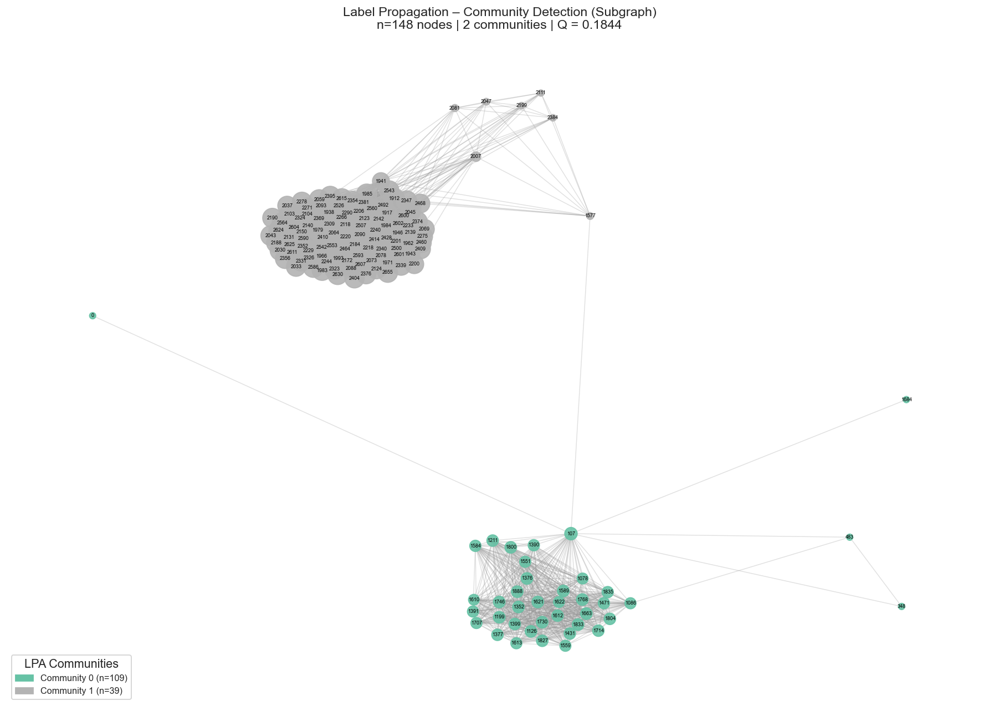

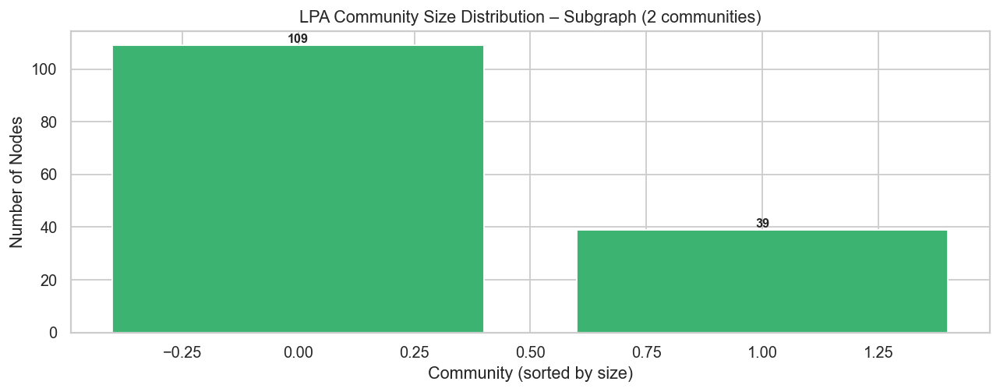

In [17]:
#  Visualise LPA subgraph communities ------------------------------------------------
# Reuse pos_gn layout from Section 5 so both visualisations are directly comparable.
cmap_lpa_sub = plt.cm.get_cmap('Set2', n_lpa_sub)
nc_lpa_sub   = [cmap_lpa_sub(lpa_sub_partition[n]) for n in G_gn.nodes()]
deg_gn_dict  = dict(G_gn.degree())
ns_lpa_sub   = [max(40, deg_gn_dict[n] * 4) for n in G_gn.nodes()]

fig, ax = plt.subplots(figsize=(14, 10))
nx.draw_networkx_nodes(G_gn, pos_gn, ax=ax,
                       node_color=nc_lpa_sub, node_size=ns_lpa_sub, alpha=0.9)
nx.draw_networkx_edges(G_gn, pos_gn, ax=ax,
                       edge_color='#999999', alpha=0.3, width=0.8)
nx.draw_networkx_labels(G_gn, pos_gn, ax=ax,
                        font_size=5, font_color='black')

patches_lpa_sub = [mpatches.Patch(color=cmap_lpa_sub(i),
                                   label=f'Community {i} (n={lpa_sub_sizes[i]})')
                   for i in range(n_lpa_sub)]
ax.legend(handles=patches_lpa_sub, loc='lower left', fontsize=9,
          title='LPA Communities', framealpha=0.85)
ax.set_title(f'Label Propagation – Community Detection (Subgraph)\n'
             f'n={G_gn.number_of_nodes()} nodes | '
             f'{n_lpa_sub} communities | Q = {lpa_sub_modularity:.4f}',
             fontsize=13)
ax.axis('off')
plt.tight_layout()
plt.savefig('ex2_lpa_sub_communities.png', bbox_inches='tight', dpi=150)
plt.show()

# Size bar chart
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(n_lpa_sub), lpa_sub_sizes, color='mediumseagreen', edgecolor='white')
for i, v in enumerate(lpa_sub_sizes):
    ax.annotate(f'{v}', xy=(i, v), ha='center', va='bottom',
                fontsize=9, fontweight='bold')
ax.set(title=f'LPA Community Size Distribution – Subgraph ({n_lpa_sub} communities)',
       xlabel='Community (sorted by size)', ylabel='Number of Nodes')
plt.tight_layout()
plt.savefig('ex2_lpa_sub_sizes.png', bbox_inches='tight')
plt.show()

---
## Section 6 – Comparison of Community Detection Results (Subgraph: LPA vs Louvain)

Both algorithms are  evaluated on the **full graph**.

In [18]:
#  Summary comparison table --------------------------------------------------------
# Both algorithms ran on the full graph (LPA).
# Key axes of comparison: scope, number of communities, modularity, complexity, approach
comparison = pd.DataFrame({
    'Metric': [
        'Graph scope',
        'Nodes analysed',
        'Edges analysed',
        'Communities detected',
        'Modularity (Q)',
        'Largest community (nodes)',
        'Smallest community (nodes)',
        'Mean community size (nodes)',
        'Time complexity',
        'Deterministic',
        'Tie handling',
        'Approach'
    ],
    'Label Propagation (LPA)': [
        'Full graph',
        G.number_of_nodes(),
        G.number_of_edges(),
        n_lpa,
        round(lpa_modularity, 4),
        lpa_sizes[0],
        lpa_sizes[-1],
        round(np.mean(lpa_sizes), 1),
        'O(m) per iteration',
        'No',
        'No (stochastic tie-breaking)',
        'Majority-label propagation'
    ],
    'Louvain': [
        'Full graph',
        G.number_of_nodes(),
        G.number_of_edges(),
        n_louvain,
        round(louvain_modularity, 4),
        louvain_sizes[0],
        louvain_sizes[-1],
        round(np.mean(louvain_sizes), 1),
        'O(n log n)',
        'Mostly deterministic',
        'Greedy modularity gain',
        'Modularity optimisation'
    ]
})

print('=== Algorithm Comparison ===')
print(comparison.to_string(index=False))

=== Algorithm Comparison ===
                     Metric      Label Propagation (LPA)                 Louvain
                Graph scope                   Full graph              Full graph
             Nodes analysed                         4039                    4039
             Edges analysed                        88234                   88234
       Communities detected                           44                      15
             Modularity (Q)                       0.7368                  0.8349
  Largest community (nodes)                         1030                     548
 Smallest community (nodes)                            2                      19
Mean community size (nodes)                         91.8                   269.3
            Time complexity           O(m) per iteration              O(n log n)
              Deterministic                           No    Mostly deterministic
               Tie handling No (stochastic tie-breaking)  Greedy modularity gain

---
## Section 6b – Comparison of Community Detection Results (Subgraph: LPA vs Girvan-Newman)

Both algorithms are now evaluated on the **identical subgraph** `G_gn`, the largest
connected component of the top-150 degree nodes, ensuring that any difference in
results reflects genuine algorithmic behaviour rather than input data differences.
Modularity scores are computed against the same reference graph in both cases.

In [19]:
# Summary comparison table ---------------------------------------------------------
comparison = pd.DataFrame({
    'Metric': [
        'Graph scope',
        'Nodes analysed',
        'Edges analysed',
        'Communities detected',
        'Modularity (Q)',
        'Largest community (nodes)',
        'Smallest community (nodes)',
        'Mean community size (nodes)',
        'Time complexity',
        'Requires k a priori?',
        'Deterministic?',
        'Approach'
    ],
    'LPA (Section 4b)': [
        'Top-150 degree subgraph',
        G_gn.number_of_nodes(),
        G_gn.number_of_edges(),
        n_lpa_sub,
        round(lpa_sub_modularity, 4),
        lpa_sub_sizes[0],
        lpa_sub_sizes[-1],
        round(np.mean(lpa_sub_sizes), 1),
        'O(m) per iteration',
        'No',
        'No (stochastic tie-breaking)',
        'Majority-label propagation'
    ],
    'Girvan-Newman (Section 5)': [
        'Top-150 degree subgraph',
        G_gn.number_of_nodes(),
        G_gn.number_of_edges(),
        best_gn_k,
        round(best_gn_q, 4),
        gn_sizes[0],
        gn_sizes[-1],
        round(np.mean(gn_sizes), 1),
        'O(m²n)',
        'No',
        'Yes',
        'Iterative edge removal (max EBC)'
    ]
})

print('=== Fair Comparison: LPA vs Girvan-Newman (same subgraph) ===')
print(comparison.to_string(index=False))

=== Fair Comparison: LPA vs Girvan-Newman (same subgraph) ===
                     Metric             LPA (Section 4b)        Girvan-Newman (Section 5)
                Graph scope      Top-150 degree subgraph          Top-150 degree subgraph
             Nodes analysed                          148                              148
             Edges analysed                         5614                             5614
       Communities detected                            2                                9
             Modularity (Q)                       0.1844                           0.1868
  Largest community (nodes)                          109                              102
 Smallest community (nodes)                           39                                1
Mean community size (nodes)                         74.0                             16.4
            Time complexity           O(m) per iteration                           O(m²n)
       Requires k a priori?           

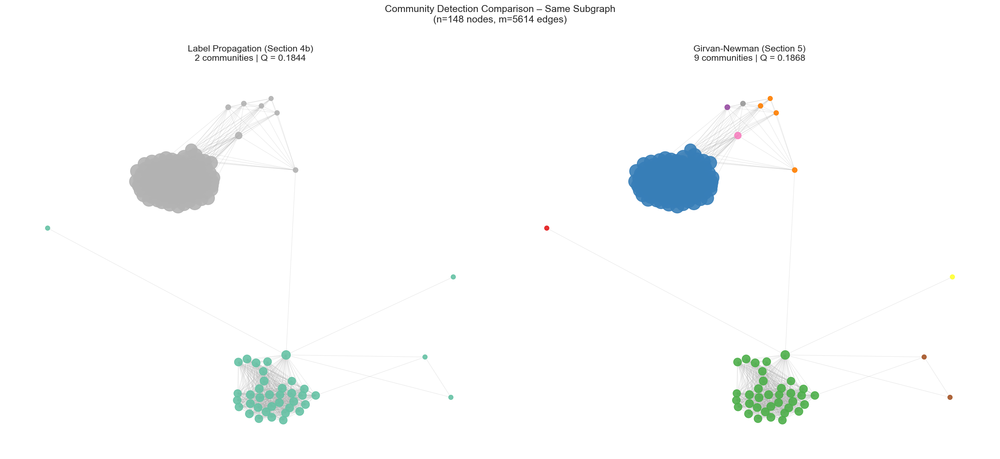

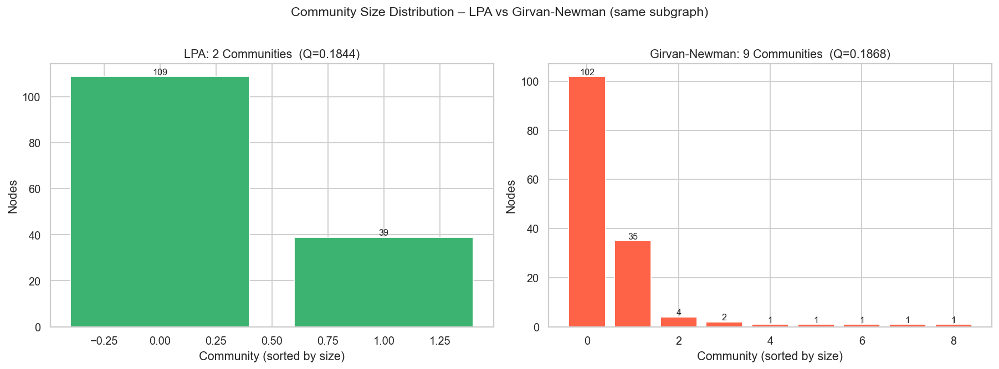

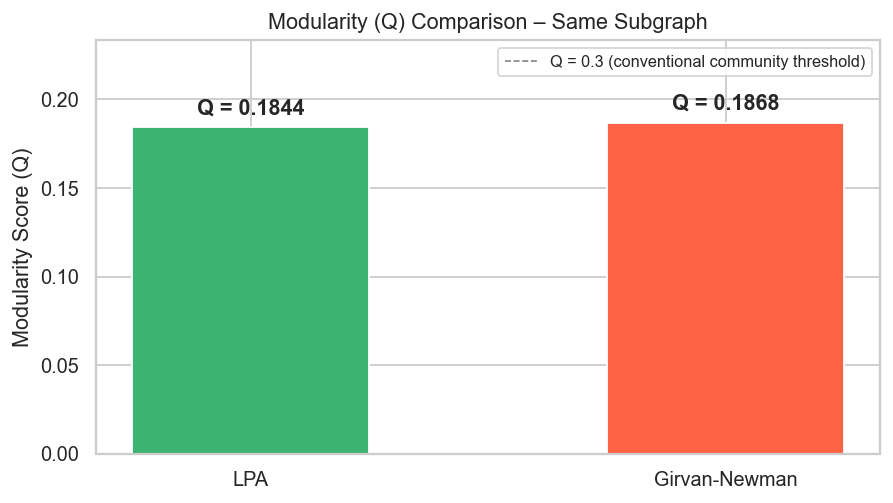


=== Exercise 2 Complete ===


In [20]:
#  Side-by-side community visualisations ----------------------------------------------
# Both plots share pos_gn so node positions are identical — differences in
# colouring directly reveal where the algorithms agree and disagree.

fig, axes = plt.subplots(1, 2, figsize=(20, 9))

# LPA
nx.draw_networkx_nodes(G_gn, pos_gn, ax=axes[0],
                       node_color=nc_lpa_sub, node_size=ns_lpa_sub, alpha=0.9)
nx.draw_networkx_edges(G_gn, pos_gn, ax=axes[0],
                       edge_color='#aaaaaa', alpha=0.25, width=0.7)
axes[0].set_title(f'Label Propagation (Section 4b)\n'
                  f'{n_lpa_sub} communities | Q = {lpa_sub_modularity:.4f}',
                  fontsize=13)
axes[0].axis('off')

# Girvan-Newman
nx.draw_networkx_nodes(G_gn, pos_gn, ax=axes[1],
                       node_color=nc_gn, node_size=ns_gn, alpha=0.9)
nx.draw_networkx_edges(G_gn, pos_gn, ax=axes[1],
                       edge_color='#aaaaaa', alpha=0.25, width=0.7)
axes[1].set_title(f'Girvan-Newman (Section 5)\n'
                  f'{best_gn_k} communities | Q = {best_gn_q:.4f}',
                  fontsize=13)
axes[1].axis('off')

plt.suptitle(f'Community Detection Comparison – Same Subgraph\n'
             f'(n={G_gn.number_of_nodes()} nodes, m={G_gn.number_of_edges()} edges)',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('ex2_side_by_side_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

#  Size distribution comparison ------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(n_lpa_sub), lpa_sub_sizes, color='mediumseagreen', edgecolor='white')
for i, v in enumerate(lpa_sub_sizes):
    axes[0].annotate(f'{v}', xy=(i, v), ha='center', va='bottom', fontsize=9)
axes[0].set(title=f'LPA: {n_lpa_sub} Communities  (Q={lpa_sub_modularity:.4f})',
            xlabel='Community (sorted by size)', ylabel='Nodes')

axes[1].bar(range(best_gn_k), gn_sizes, color='tomato', edgecolor='white')
for i, v in enumerate(gn_sizes):
    axes[1].annotate(f'{v}', xy=(i, v), ha='center', va='bottom', fontsize=9)
axes[1].set(title=f'Girvan-Newman: {best_gn_k} Communities  (Q={best_gn_q:.4f})',
            xlabel='Community (sorted by size)', ylabel='Nodes')

plt.suptitle('Community Size Distribution – LPA vs Girvan-Newman (same subgraph)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('ex2_size_comparison.png', bbox_inches='tight')
plt.show()

#  Modularity bar chart -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4))
alg_names = [f'LPA', f'Girvan-Newman']
q_values  = [lpa_sub_modularity, best_gn_q]
colors    = ['mediumseagreen', 'tomato']
bars = ax.bar(alg_names, q_values, color=colors, edgecolor='white', width=0.5)
for bar, q in zip(bars, q_values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
            f'Q = {q:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=12)
ax.set(title='Modularity (Q) Comparison – Same Subgraph',
       ylabel='Modularity Score (Q)',
       ylim=(0, max(q_values) * 1.25))
ax.axhline(0.3, color='grey', linestyle='--', linewidth=0.9,
           label='Q = 0.3 (conventional community threshold)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('ex2_modularity_comparison.png', bbox_inches='tight')
plt.show()

print('\n=== Exercise 2 Complete ===')